# 06. Diagnosis dan pengembangan output PageSpec

Notebook read-only untuk sesi AI-011, 13 Oktober 2026. Alur: diagnosis model 40 update, fit 400 update, latihan sintetis terpisah, generasi development, dan final yang dikunci sebelum training. Hasil mentah ditampilkan tanpa repair. Run All tidak memulai training.

Tujuan: Mini GPT proyek menghasilkan JSON PageSpec yang valid dan sesuai instruksi yang didukung. Skor sintetis tidak membuktikan prompt bebas atau kualitas website di browser.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if ROOT.name == "notebooks": ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
def read(path): return json.loads((ROOT / path).read_text(encoding="utf-8"))
progress = read("reports/training/CURRICULUM_PROGRESS_2026-10-13.json")
print("Kernel interpreter:", sys.executable)
print("Training run IDs:", progress["runs"])

Kernel interpreter: F:\Generative_AI\Vibe_Coding_Proyek_1\.venv\Scripts\python.exe
Training run IDs: ['TRAIN-013']


## 1. Mengapa pilot awal gagal

Training/generation prefix sama, tetapi model belum belajar token pembuka JSON pada 40 update. Setelah 400 update, empat train examples bisa disalin, sementara validation memburuk. Output train adalah bukti hafalan, bukan generalisasi. Pilot test terdahulu tidak dipakai untuk tuning ini.

In [2]:
for path in ("reports/training/TRAIN-006-DEV_diagnostic.json", "reports/training/TRAIN-007-LAST-DEV_diagnostic.json"):
    report = read(path)
    print("\n", path)
    for split in ("train", "validation"):
        rows = [r for r in report["records"] if r["split"] == split]
        print(split, "valid:", sum(r["schema_valid"] for r in rows), "/", len(rows),
              "token correct:", sum(r["teacher_forced_correct"] for r in rows),
              "/", sum(r["target_tokens"] for r in rows))
    print("Prefix match:", all(r["prefix_ids_match"] for r in report["records"]))


 reports/training/TRAIN-006-DEV_diagnostic.json
train valid: 0 / 4 token correct: 794 / 1401
validation valid: 0 / 4 token correct: 586 / 1404
Prefix match: True

 reports/training/TRAIN-007-LAST-DEV_diagnostic.json
train valid: 4 / 4 token correct: 1401 / 1401
validation valid: 0 / 4 token correct: 723 / 1404
Prefix match: True


## 2. Corpus latihan sintetis dan provenance

Programmatic contract: v1/v2 memakai 288 kombinasi nama; v3 memakai 2.400 nama brand fiktif dengan variasi teks utama. V4 menambah 7.548 train-only copy drills dari BPE alphabetic vocabulary <=6 karakter. Drill dapat mencakup 4.072 dari 4.998 eligible token IDs; 926 belum terwakili oleh konstruksi nama yang dicoba. Tidak mengklaim seluruh vocabulary tersalin. Nama dipartisi sebagai keluarga; komponen/resep dan subword dipakai bersama antar partition. Semua target deterministik divalidasi schema/context, tanpa reviewer manusia palsu. Dua belas reviewed annotations dan corpus HF tetap terpisah.

Curriculum bukan benchmark layout baru. Harga dan testimonial hanya contoh fiktif yang diminta eksplisit. BPE tetap dari train pretraining. Manifest mencatat cache/hash, serialization dan kriteria final sebelum training.

In [3]:
for path in sorted((ROOT / "reports/data").glob("SYNTHETIC_CURRICULUM_*.json")):
    data = json.loads(path.read_text(encoding="utf-8"))
    print(path.name, "revision:", data["revision"])
    print("Counts:", data["counts"])
    print("Review kind:", data["review_kind"], "human reviewed:", data["human_reviewed_rows"])
    print("Max sequence:", data["max_sequence_tokens"])
    print("Train coverage:", data["coverage"]["train"])
    print("Serialization:", data.get("serialization", "sorted_keys"))
    print("Final suite:", data["final_suite"], "acceptance:", data["acceptance"])

SYNTHETIC_CURRICULUM_V1.json revision: synthetic-contract-v1
Counts: {'train': {'rows': 11040, 'families': 230}, 'validation': {'rows': 1392, 'families': 29}, 'test': {'rows': 1392, 'families': 29}}
Review kind: programmatic_contract human reviewed: 0
Max sequence: 856
Train coverage: {'sections': {'navbar': 11040, 'hero': 10120, 'footer': 11040, 'feature_grid': 4600, 'text_section': 920, 'pricing_table': 1840, 'testimonial': 920, 'contact_form': 2760}, 'interactions': {'menu_toggle': 5520, 'form_validate': 2760, 'accordion': 920, 'tabs': 920, 'filter': 920, 'modal': 920}}
Serialization: sorted_keys
Final suite: {'path': 'data\\processed\\curriculum\\v1\\final_prompts.jsonl', 'sha256': '87e9eaf673632ce5e2d28f8e5f47215a62ccea9136191efbe1ae17adcdbeeafa', 'count': 48} acceptance: {'schema_valid_rate': 0.95, 'exact_contract_rate': 0.9, 'repair_allowed': False}
SYNTHETIC_CURRICULUM_V2.json revision: synthetic-contract-v2
Counts: {'train': {'rows': 11040, 'families': 230}, 'validation': {'ro

## 3. Target/prompt mask dan konfigurasi

Prompt dan padding labels -100, target JSON + EOS labels aktif. Next-token sudah digeser. Cache dapat dibaca bila data lokal tersedia; setelah clone, laporan kecil tetap tersedia. Semua eksperimen memakai model proyek 14,19 juta parameter dan parent pretraining dari random weights, bukan model bahasa pretrained.

In [4]:
reports = [read(f"reports/training/{run}.json") for run in progress["runs"]]
for r in reports:
    print(r["run_id"], "status:", r["status"], "global step:", r["global_step"], "resume parent:", r["resume_parent"])
    print("Initial/final validation:", r["initial_validation"]["loss"], r.get("final_validation", {}).get("loss"))
    print("Total target tokens:", r.get("total_train_tokens"), "trainer seconds:", r["wall_seconds"])
    print("GPU GiB allocated/reserved:", r["peak_allocated_bytes"] / 2**30, r["peak_reserved_bytes"] / 2**30)
    print("Project pretraining ancestor:", r["config"]["lineage"]["pretraining_parent"])
    print("Curriculum parent, if continuation:", r["config"]["lineage"].get("curriculum_parent"))
    print("Config:", json.dumps({k:v for k,v in r["config"].items() if k not in {"lineage", "model_config"}}, indent=2))
cfg = reports[-1]["config"]
directory = ROOT / cfg.get("dataset_dir", "data/processed/curriculum/v1")
if (directory / "manifest.json").exists():
    from src.data.curriculum import CurriculumDataset
    dataset = CurriculumDataset(json.loads((directory / "manifest.json").read_text()), "train")
    sample = dataset[0]
    print("Shape:", sample["input_ids"].shape, "Target labels:", int((sample["labels"] != -100).sum()))
    if "name_loss_weight" in cfg:
        import numpy as np
        weights = read(str((directory / "name_weights.json").relative_to(ROOT)))
        weighted_dataset = CurriculumDataset(json.loads((directory / "manifest.json").read_text()), "train", ROOT / weights["path"])
        weighted_sample = weighted_dataset[0]
        values, counts = np.unique(weighted_sample["loss_weights"].numpy(), return_counts=True)
        print("Weight distribution:", dict(zip(values.tolist(), counts.tolist())))
        print("Prompt/padding weights zero:", bool((weighted_sample["loss_weights"][weighted_sample["labels"] == -100] == 0).all()))
else: print("Cache tetap lokal; persiapkan curriculum untuk membaca batch.")

TRAIN-013 status: completed global step: 3600 resume parent: None
Initial/final validation: 0.005658693556845027 0.007606502481371312
Total target tokens: 10781936 trainer seconds: 434.22006370004965
GPU GiB allocated/reserved: 2.092996120452881 2.330078125
Project pretraining ancestor: {'checkpoint_sha256': '49e03ebb37f01619de9dc93a55f6828367d84fd34380986bfa15597d9583831c', 'phase': 'pretrain', 'global_step': 1200, 'pretrain_fingerprint': {'version': 1, 'tokenizer_sha256': 'f7d5410d5963b3504bc09a4f6bf29e695cb8c6ba64041bfe1596a13cecb210d7', 'assignment_sha256': 'b827fdf80f0a20577a674a2ef4b70159da92a472e2535d5458c410c0398ab55b', 'source_revisions': [{'id': 'vulcan', 'revision': '19d2a482c78554e59feca0ce2b50fb7835e90c6f', 'license': 'mit', 'rows': 5000}, {'id': 'websight_v01', 'revision': 'b11f8172f89c992b56ac702319e02c428cca4a4e', 'license': 'cc-by-4.0', 'rows': 20000}, {'id': 'websight_v02', 'revision': 'b11f8172f89c992b56ac702319e02c428cca4a4e', 'license': 'cc-by-4.0', 'rows': 30000}]

Shape: torch.Size([1024]) Target labels: 368
Weight distribution: {0.0: 656, 1.0: 328, 16.0: 40}
Prompt/padding weights zero: True


## 4. Kurva aktual

Grafik berasal dari metric JSONL aktual pada run IDs yang ditampilkan. Pada v5, train memakai weighted mean CE nama16x; validation ordinary mean CE. Nilainya tidak dibandingkan langsung sebagai ukuran generalization gap. Penilaian semantik memakai raw generation.

Titik validation terduplikasi saat optimizer resume dirangkum berdasarkan step. Token total saat resume bersifat kumulatif, jangan menjumlahkan parent/child. Continuation optimizer baru memakai step0 lagi dan grafik tahap terpisah. Loss rendah belum membuktikan nama atau atribut tepat.

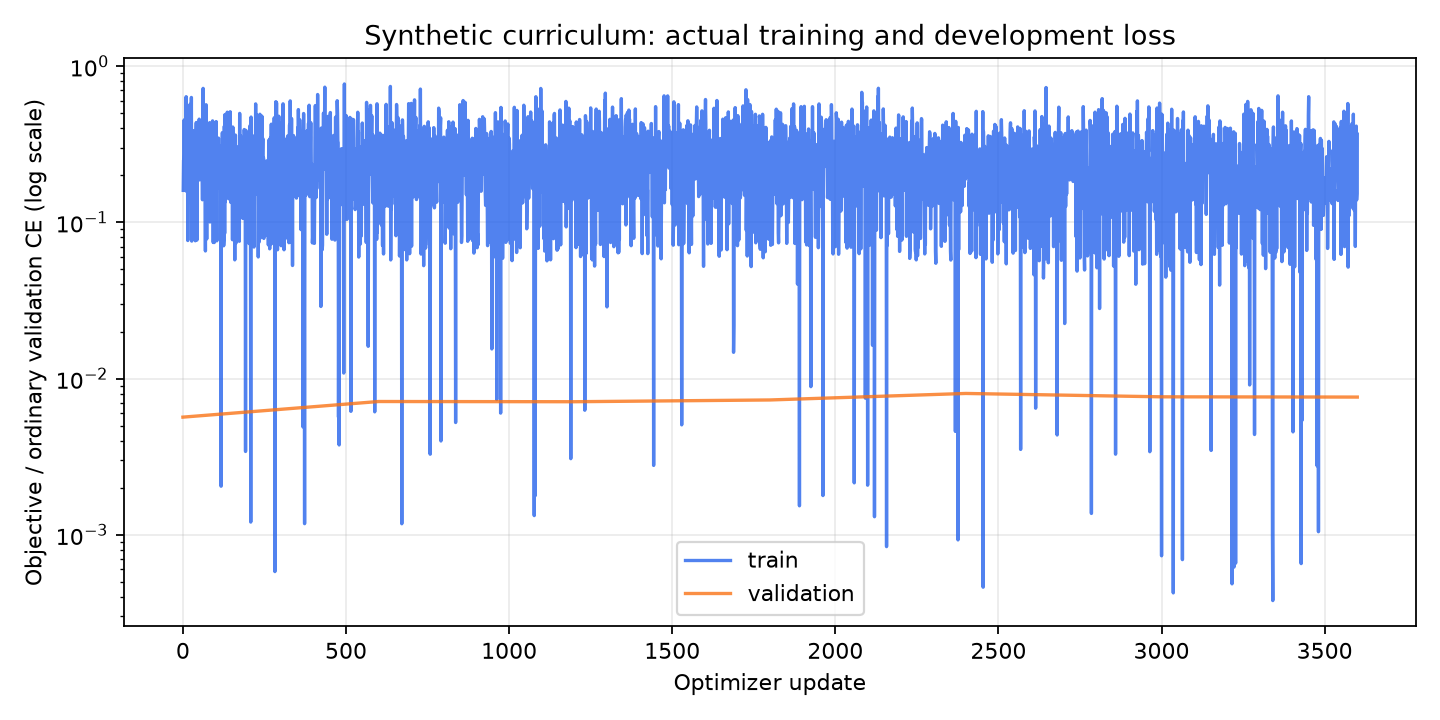

Validation: [(0, 0.005658693556845027), (600, 0.007125048095856997), (1200, 0.0071023816042049305), (1800, 0.007289913469014493), (2400, 0.008024086080411292), (3000, 0.007634966195303452), (3600, 0.007606502481371312)]


In [5]:
from IPython.display import display, Image
display(Image(filename=str(ROOT / "reports/training/CURRICULUM_LOSS_2026-10-13.png")))
print("Validation:", [(r["step"], r["loss"]) for r in progress["curve"]["validation"]])

## 5. Development vs final

Development dipakai untuk diagnosis, final dikunci sebelum training dan hanya dibaca setelah budget selesai menggunakan checkpoint best menurut validation. Kriteria tidak diturunkan setelah melihat hasil: >=95% schema valid dan >=90% target contract tepat. Kedua skor dihitung pada output mentah.

Final sintetis ini memakai template/resep yang diketahui dan nama berbeda. Hasilnya tidak dibandingkan langsung dengan test kode atau empat human-reviewed test sebelumnya.

In [6]:
for path in sorted((ROOT / "reports/training").glob("*_curriculum_evaluation.json")):
    r = json.loads(path.read_text(encoding="utf-8"))
    print(path.name, "split:", r["split"], "step:", r["checkpoint_step"],
          "valid:", r["schema_valid"], "/", r["count"], "exact:", r["exact_contract"], "/", r["count"],
          "gate:", r["contract_gate_passed"])
    print("Field matches:", r.get("exact_field_matches", "Belum direkam pada laporan lama"))
final = read(progress["final_report"])
print("\nFinal selected report:", json.dumps(final, indent=2))

TRAIN-008-DEV_curriculum_evaluation.json split: validation step: 800 valid: 22 / 24 exact: 0 / 24 gate: False
Field matches: Belum direkam pada laporan lama
TRAIN-009-DEV_curriculum_evaluation.json split: validation step: 2400 valid: 24 / 24 exact: 1 / 24 gate: False
Field matches: {'title': 24, 'style_mode': 24, 'theme': 1, 'sections': 24, 'interactions': 24}
TRAIN-010-DEV_curriculum_evaluation.json split: validation step: 2400 valid: 24 / 24 exact: 24 / 24 gate: True
Field matches: {'title': 24, 'style_mode': 24, 'theme': 24, 'sections': 24, 'interactions': 24}
TRAIN-010-FINAL_curriculum_evaluation.json split: final step: 2400 valid: 48 / 48 exact: 48 / 48 gate: True
Field matches: {'title': 48, 'style_mode': 48, 'theme': 48, 'sections': 48, 'interactions': 48}
TRAIN-011-DEV_curriculum_evaluation.json split: validation step: 4800 valid: 24 / 24 exact: 20 / 24 gate: False
Field matches: {'title': 20, 'style_mode': 24, 'theme': 24, 'sections': 20, 'interactions': 24}
TRAIN-012-DEV_curr

## 6. Prompt dan hasil asli model

JSON di bawah berasal dari generasi model, bukan target jawaban. File output penuh tetap lokal. Tiga contoh memperlihatkan CSS biasa/Tailwind serta komponen berbeda; periksa nama, warna, font, section dan interaksi terhadap prompt.

In [7]:
raw_path = ROOT / final["outputs_path"]
if raw_path.exists():
    rows = json.loads(raw_path.read_text(encoding="utf-8"))
    chosen = [next(r for r in rows if r["recipe"] == recipe and r["target_spec"]["style_mode"] == style)
              for recipe, style in (("features_contact", "plain_css"), ("pricing", "tailwind"), ("accordion", "tailwind"))]
    for row in chosen:
        print("\nPROMPT:", row["prompt"])
        print("RAW MODEL OUTPUT:", row["raw_output"])
        print("Status:", row["parse_status"], "schema valid:", row["parsed_spec"] is not None,
              "exact:", row["exact_contract"], "EOS:", row["stop_reason"])
else: print("Raw generation file tetap lokal; lihat metrik tracked di atas.")


PROMPT: Rancang halaman Indonesia bernama Dapur Ranika menggunakan CSS biasa. Aksen #8b5cf6, latar putih, teks #111827 dan font serif. Tampilkan navbar Beranda, hero centered dengan judul nama situs, dan footer nama situs. Teks utama: Kami membantu mitra usaha untuk merencanakan kegiatan bersama. Navbar statis. Tambahkan dua kartu layanan: Kualitas dan Kenyamanan. Tambahkan form Hubungi Kami, kolom Nama, Email dan Pesan, tombol Kirim, serta validasi form.
RAW MODEL OUTPUT: {"interactions":[{"target_id":"contact","type":"form_validate"}],"language":"id","schema_version":"1.0","style_mode":"plain_css","theme":{"background":"#ffffff","font":"serif","primary":"#8b5cf6","text":"#111827"},"sections":[{"id":"nav","props":{"brand":"Dapur Ranika","links":[{"href":"#main","label":"Beranda"}]},"type":"navbar"},{"id":"main","props":{"heading":"Dapur Ranika","layout":"centered","text":"Kami membantu mitra usaha untuk merencanakan kegiatan bersama."},"type":"hero"},{"id":"features","props":{"headin

## 7. Penyalinan nama dan ekspor website

Final v2 48/48 tepat belum membuktikan nama baru: Studio Cakrawala menjadi Studio Cahaya. V3 development20/24 tepat, empat kesalahan Workstaralasa: subword sta tidak muncul dalam title train. V4 menambah drill subword tetapi final43/48exact89,58% gagal threshold90%. Semua kegagalan tetap dicatat.

V5 menguji name-token objective16x, train/validation byte-identik v4, fresh final240brandstrings seed8675309. Suite48 baru dikunci sebelum training. Validation/test tetap ordinary CE; architecture/BPE tetap. Ancestor pretraining tercatat. Cakrawala dikecualikan dari latihan, namun probe yang pernah dibaca tetap development.

Audit berikut memeriksa raw artifacts, bukan menjalankan generasi atau memperbaiki nama. Renderer hanya membuat website bila schema dan kontrak prompt lulus. Preview browser belum terverifikasi karena alat menolak protokol file lokal.

In [8]:
for path in sorted((ROOT / "reports").glob("PROMPT_CONTRACT_AUDIT_*.json")):
    audit = json.loads(path.read_text(encoding="utf-8"))
    print(path.name, "Final contract:", audit["final_contract_accepted"], "/", audit["final_count"])
    for row in audit["runtime"]:
        print("Runtime:", row["directory"], "accepted now:", row["contract_accepted_now"])
        print("Errors:", row["contract"]["errors"])
for path in sorted((ROOT / "reports").glob("GENERATED_OUTPUTS_*.json")):
    exported = json.loads(path.read_text(encoding="utf-8"))
    print(path.name, "Website count:", exported["output_count"], "Gallery:", exported["output_dir"])
    print("Browser evaluated:", exported["browser_evaluated"])
print("Contoh prompt:", (ROOT / "examples/prompts/studio_cakrawala.txt").read_text(encoding="utf-8"))

PROMPT_CONTRACT_AUDIT_V2.json Final contract: 48 / 48
Runtime: outputs\generated_websites\studio-cakrawala-v1 accepted now: False
Errors: ["title: diminta 'Studio Cakrawala', model menghasilkan 'Studio Cahaya'", 'Section nav: isi tidak sesuai kontrak prompt', 'Section footer: isi tidak sesuai kontrak prompt', 'Section main: isi tidak sesuai kontrak prompt']
PROMPT_CONTRACT_AUDIT_V4.json Final contract: 43 / 48
Runtime: outputs\generated_websites\studio-cakrawala-v2 accepted now: True
Errors: []
Runtime: outputs\generated_websites\kafe-senandika-v1 accepted now: False
Errors: ["title: diminta 'Kafe Senandika', model menghasilkan 'Kafe Senanka'", 'Section nav: isi tidak sesuai kontrak prompt', 'Section footer: isi tidak sesuai kontrak prompt', 'Section main: isi tidak sesuai kontrak prompt']
Runtime: outputs\generated_websites\studio-cakrawala-tailwind-v1 accepted now: True
Errors: []
GENERATED_OUTPUTS_2026-10-13.json Website count: 48 Gallery: outputs\generated_websites\AI-011-v2
Browse

## 8. Contoh generasi untuk nama baru

Raw output berikut berasal dari runtime model, termasuk status kontrak. Ini probe development, bukan final independen. Keluaran gagal tetap disimpan, tidak diperbaiki. Contoh file HTML/CSS/JS ada dalam folder output yang diterima. Run All hanya membaca hasil.

Untuk mencoba input sendiri, salin contoh prompt, lalu jalankan CLI melalui RUN logger sesuai docs/GENERATING_WEBSITES.md. Prompt bebas di luar format yang didukung dapat ditolak. Tidak menjalankan training/generasi CUDA otomatis dari notebook ini.

In [9]:
for audit_path in sorted((ROOT / "reports").glob("PROMPT_CONTRACT_AUDIT_*.json")):
    audit = json.loads(audit_path.read_text(encoding="utf-8"))
    for row in audit["runtime"]:
        if not row["contract_accepted_now"]: continue
        directory = ROOT / row["directory"]
        if not directory.exists(): continue
        print("\nRUNTIME:", row["directory"])
        print("PROMPT:", (directory / "prompt.txt").read_text(encoding="utf-8"))
        print("RAW MODEL OUTPUT:", (directory / "raw_output.txt").read_text(encoding="utf-8"))
        print("Preview:", directory / "index.html")
        print("Model and validation metadata:", (directory / "generation.json").read_text(encoding="utf-8"))


RUNTIME: outputs\generated_websites\studio-cakrawala-v2
PROMPT: Buat website Indonesia bernama Studio Cakrawala menggunakan CSS biasa. Aksen #2563eb, latar putih, teks #111827 dan font sans. Tampilkan navbar Beranda, hero centered dengan judul nama situs, dan footer nama situs. Teks utama: Temukan layanan pilihan kami. Gunakan menu responsif. Tambahkan dua kartu layanan: Desain dan Konsultasi. Tambahkan form Hubungi Kami, kolom Nama, Email dan Pesan, tombol Kirim, serta validasi form.

RAW MODEL OUTPUT: {"interactions":[{"target_id":"nav","type":"menu_toggle"},{"target_id":"contact","type":"form_validate"}],"language":"id","schema_version":"1.0","style_mode":"plain_css","theme":{"background":"#ffffff","font":"sans","primary":"#2563eb","text":"#111827"},"sections":[{"id":"nav","props":{"brand":"Studio Cakrawala","links":[{"href":"#main","label":"Beranda"}]},"type":"navbar"},{"id":"main","props":{"heading":"Studio Cakrawala","layout":"centered","text":"Temukan layanan pilihan kami."},"t

### Mencoba prompt sendiri

Sel berikut default tidak menjalankan GPU generation. Aktifkan RUN_GENERATION setelah mengedit file prompt sesuai format terlatih. Semua run dicatat dengan ID baru. Runtime TRAIN-012 gagal overall gate43/48; --development mengizinkan research demo dengan validasi per output. Tidak memperbaiki jawaban atau menyatakan siap produksi.

TRAIN-013 weighted objective tidak memperbaiki full validation; best step0 identik dengan parent melalui77tensor. Final v5 tetap belum dibaca. Grafik TRAIN-013 menunjukkan eksperimen gagal, sedangkan final report/runtime notebook ini berasal dari TRAIN-012.

In [10]:
import subprocess
from datetime import datetime
RUN_GENERATION = False
PROMPT_FILE = ROOT / "examples/prompts/studio_cakrawala.txt"
if RUN_GENERATION:
    output = "outputs/generated_websites/notebook-" + datetime.now().strftime("%Y%m%d-%H%M%S-%f")
    command = [sys.executable, "qa/run_logged.py", "--label", "notebook_prompt_generation", "--",
        sys.executable, "-m", "qa.generate_website", "--checkpoint", "checkpoints/TRAIN-012/best.pt",
        "--evidence", "reports/training/TRAIN-012-FINAL_curriculum_evaluation.json", "--development",
        "--prompt-file", str(PROMPT_FILE), "--output", output]
    subprocess.run(command, cwd=ROOT, check=True)
    print("Output:", ROOT / output)
else: print("GPU generation disabled; edit prompt/flag to run explicitly.")
selection = read("reports/training/TRAIN-013_SELECTION_DIAGNOSTIC.json")
print("Checkpoint selection:", selection)

GPU generation disabled; edit prompt/flag to run explicitly.
Checkpoint selection: {'parent': 'TRAIN-012/best', 'candidate': 'TRAIN-013/best', 'selected_step': 0, 'model_tensors_identical': True, 'parameter_tensors': 77, 'parent_sha256': '791a365463710f73dbfbba767bd8bd17f5b4442e8f6137a92ec8c5888d1a2ed3', 'candidate_sha256': 'e44030d363afcc0c70b305ead82ba8bf1510ef53761e913e79b2697a4d81d28a', 'decision': 'No measured improvement from name-weighted training; keep TRAIN-012 for research runtime; v5 final remains unread'}


## 9. Batas kemampuan dan penggunaan

- Human approval dan programmatic contract adalah dua jenis bukti yang berbeda. Gate production reviewed menolak checkpoint sintetis secara eksplisit.
- Kesimpulan berlaku pada format prompt/katalog yang dilatih. Prompt bebas, fakta bisnis nyata dan layout baru membutuhkan data/evaluasi lain.
- JSON/schema/contract yang tepat belum membuktikan rendering, aksesibilitas atau perilaku browser. Hasil ekspor/browser, bila dilakukan, dicatat terpisah.
- Tidak ada repair JSON, fallback template yang diklaim sebagai hasil model, pemilihan checkpoint dari test, atau penggantian model dengan pretrained LLM.
- Lihat log AI-011 dan LOG_TRAINING untuk semua RUN, termasuk stop/resume, kegagalan dan eksperimen yang tidak mencapai gate.